In [1]:
!pip install pandas numpy scipy matplotlib seaborn tqdm

In [2]:
from google.colab import drive
drive.mount('/content/drive')
CLICKS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-clicks.dat"

BUYS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-buys.dat"

Mounted at /content/drive


In [4]:
# ============================================================
# RELOAD CLICKS FOR HMM
# ============================================================

import pandas as pd

CLICKS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-clicks.dat"

print("Chargement clicks...")

clicks = pd.read_csv(
    CLICKS_PATH,
    header=None,
    names=["session_id", "timestamp", "item_id", "category"],
    dtype={
        "session_id": "int64",
        "item_id": "string",
        "category": "string"
    },
    low_memory=False
)

# timestamps
clicks["timestamp"] = pd.to_datetime(
    clicks["timestamp"],
    errors="coerce",
    utc=True
)

clicks = clicks.dropna(subset=["timestamp"])

# ============================================================
# SAMPLE 100000 SESSIONS
# ============================================================

sessions = clicks["session_id"].unique()[:100000]

clicks = clicks[
    clicks["session_id"].isin(sessions)
]

print("Clicks shape:", clicks.shape)

clicks.head()

Chargement clicks...
Clicks shape: (395698, 4)


,session_id,timestamp,item_id,category
0,1,2014-04-07 10:51:09.277000+00:00,214536502,0
1,1,2014-04-07 10:54:09.868000+00:00,214536500,0
2,1,2014-04-07 10:54:46.998000+00:00,214536506,0
3,1,2014-04-07 10:57:00.306000+00:00,214577561,0
4,2,2014-04-07 13:56:37.614000+00:00,214662742,0


In [6]:
# =========================================
# MDP COMPLET — VALUE ITERATION + GAMMA
# Version Colab complète et stable
# =========================================

import numpy as np
import pandas as pd

# ===============================
# 1. STATES
# ===============================

states = [
    "Low_Fast", "Low_Normal", "Low_Slow",
    "Medium_Fast", "Medium_Normal", "Medium_Slow",
    "High_Fast", "High_Normal", "High_Slow"
]

actions = ["pub", "promo", "rec", "nothing"]

# ===============================
# 2. MATRICE DE TRANSITION DE BASE P(s'|s)
# Exemple cohérent avec ton funnel
# ===============================

P_base = {
    "Low_Fast": {
        "Low_Fast": 0.60,
        "Medium_Fast": 0.30,
        "High_Fast": 0.10
    },
    "Low_Normal": {
        "Low_Normal": 0.65,
        "Medium_Normal": 0.25,
        "High_Normal": 0.10
    },
    "Low_Slow": {
        "Low_Slow": 0.70,
        "Medium_Slow": 0.20,
        "High_Slow": 0.10
    },

    "Medium_Fast": {
        "Medium_Fast": 0.60,
        "High_Fast": 0.25,
        "Low_Fast": 0.15
    },
    "Medium_Normal": {
        "Medium_Normal": 0.65,
        "High_Normal": 0.20,
        "Low_Normal": 0.15
    },
    "Medium_Slow": {
        "Medium_Slow": 0.70,
        "High_Slow": 0.14,
        "Low_Slow": 0.16
    },

    "High_Fast": {
        "High_Fast": 0.80,
        "Medium_Fast": 0.20
    },
    "High_Normal": {
        "High_Normal": 0.82,
        "Medium_Normal": 0.18
    },
    "High_Slow": {
        "High_Slow": 0.85,
        "Medium_Slow": 0.15
    }
}

# ===============================
# 3. BUILD P(s'|s,a)
# Actions modifient les transitions
# ===============================

def normalize_dict(d):
    total = sum(d.values())
    return {k: v / total for k, v in d.items()}


def build_P_with_actions(P_base):
    P_actions = {}

    for a in actions:
        P_actions[a] = {}

        for s in states:
            probs = P_base[s].copy()

            # action pub : aide surtout les Low à passer vers Medium
            if a == "pub" and s.startswith("Low"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("Medium"):
                        probs[s_next] += 0.20
                    elif s_next == s:
                        probs[s_next] = max(0, probs[s_next] - 0.20)

            # action promo : aide surtout Medium à passer vers High
            if a == "promo" and s.startswith("Medium"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("High"):
                        probs[s_next] += 0.20
                    elif s_next == s:
                        probs[s_next] = max(0, probs[s_next] - 0.20)

            # action rec : stabilise High et finalise l'intention
            if a == "rec" and s.startswith("High"):
                for s_next in list(probs.keys()):
                    if s_next.startswith("High"):
                        probs[s_next] += 0.10
                    elif s_next.startswith("Medium"):
                        probs[s_next] = max(0, probs[s_next] - 0.10)

            # nothing : aucun changement

            P_actions[a][s] = normalize_dict(probs)

    return P_actions


P_actions = build_P_with_actions(P_base)

# ===============================
# 4. REWARDS R(s,a)
# ===============================

def build_rewards():

    state_value = {
        "Low_Fast": 0,
        "Low_Normal": -5,
        "Low_Slow": -10,

        "Medium_Fast": 20,
        "Medium_Normal": 10,
        "Medium_Slow": 5,

        "High_Fast": 100,
        "High_Normal": 70,
        "High_Slow": 40
    }

    action_cost = {
        "pub": -2,
        "promo": -5,
        "rec": -1,
        "nothing": 0
    }

    R = {}

    for s in states:
        R[s] = {}

        for a in actions:
            reward = state_value[s] + action_cost[a]

            # boost stratégique : Medium_Slow répond bien à la promo
            if s == "Medium_Slow" and a == "promo":
                reward += 20

            R[s][a] = reward

    return R


R = build_rewards()

# ===============================
# 5. VALUE ITERATION
# ===============================

def value_iteration(P, R, gamma=0.9, theta=1e-5, max_iter=500):

    V = {s: 0.0 for s in states}

    for iteration in range(max_iter):

        delta = 0
        V_new = {}

        for s in states:
            action_values = []

            for a in actions:
                value = R[s][a]

                for s_next, prob in P[a][s].items():
                    value += gamma * prob * V[s_next]

                action_values.append(value)

            V_new[s] = max(action_values)
            delta = max(delta, abs(V_new[s] - V[s]))

        V = V_new

        if delta < theta:
            print(f"Convergence atteinte en {iteration} itérations")
            break

    return V

# ===============================
# 6. EXTRACT POLICY
# ===============================

def extract_policy(P, R, V, gamma=0.9):

    policy = {}

    for s in states:
        best_action = None
        best_value = -np.inf

        for a in actions:
            value = R[s][a]

            for s_next, prob in P[a][s].items():
                value += gamma * prob * V[s_next]

            if value > best_value:
                best_value = value
                best_action = a

        policy[s] = best_action

    return policy

# ===============================
# 7. TEST MULTIPLE GAMMA
# ===============================

gammas = [0.3, 0.6, 0.9]

all_results = {}

for gamma in gammas:

    print("\n" + "="*45)
    print(f"RESULTATS POUR GAMMA = {gamma}")
    print("="*45)

    V = value_iteration(P_actions, R, gamma=gamma)
    policy = extract_policy(P_actions, R, V, gamma=gamma)

    results_df = pd.DataFrame({
        "Etat": states,
        "V(s)": [round(V[s], 2) for s in states],
        "Action optimale": [policy[s] for s in states]
    })

    display(results_df)

    all_results[gamma] = results_df

# ===============================
# 8. COMPARAISON DES POLITIQUES
# ===============================

comparison = pd.DataFrame({
    "Etat": states,
    "Gamma 0.3": all_results[0.3]["Action optimale"].values,
    "Gamma 0.6": all_results[0.6]["Action optimale"].values,
    "Gamma 0.9": all_results[0.9]["Action optimale"].values,
})

print("\n===== COMPARAISON DES POLITIQUES =====")
display(comparison)


RESULTATS POUR GAMMA = 0.3
Convergence atteinte en 14 itérations


,Etat,V(s),Action optimale
0,Low_Fast,9.25,nothing
1,Low_Normal,-0.82,nothing
2,Low_Slow,-7.96,pub
3,Medium_Fast,38.57,promo
4,Medium_Normal,19.53,nothing
5,Medium_Slow,29.74,promo
6,High_Fast,137.20,rec
7,High_Normal,95.95,rec
8,High_Slow,55.49,nothing



RESULTATS POUR GAMMA = 0.6
Convergence atteinte en 32 itérations


,Etat,V(s),Action optimale
0,Low_Fast,58.14,pub
1,Low_Normal,26.94,pub
2,Low_Slow,10.74,pub
3,Medium_Fast,108.09,promo
4,Medium_Normal,63.03,promo
5,Medium_Slow,57.65,promo
6,High_Fast,229.32,rec
7,High_Normal,160.77,rec
8,High_Slow,94.72,rec



RESULTATS POUR GAMMA = 0.9
Convergence atteinte en 151 itérations


,Etat,V(s),Action optimale
0,Low_Fast,596.72,pub
1,Low_Normal,386.49,pub
2,Low_Slow,232.71,pub
3,Medium_Fast,684.10,promo
4,Medium_Normal,453.73,promo
5,Medium_Slow,298.47,promo
6,High_Fast,845.10,rec
7,High_Normal,591.10,rec
8,High_Slow,361.59,rec



===== COMPARAISON DES POLITIQUES =====


,Etat,Gamma 0.3,Gamma 0.6,Gamma 0.9
0,Low_Fast,nothing,pub,pub
1,Low_Normal,nothing,pub,pub
2,Low_Slow,pub,pub,pub
3,Medium_Fast,promo,promo,promo
4,Medium_Normal,nothing,promo,promo
5,Medium_Slow,promo,promo,promo
6,High_Fast,rec,rec,rec
7,High_Normal,rec,rec,rec
8,High_Slow,nothing,rec,rec


À gamma = 0.9, ta politique devient très claire :

Niveau	Action optimale
Low	pub
Medium	promo
High	rec

,Gamma 0.3,Gamma 0.6,Gamma 0.9
Etat,,,
Low_Fast,9.25,58.14,596.72
Low_Normal,-0.82,26.94,386.49
Low_Slow,-7.96,10.74,232.71
Medium_Fast,38.57,108.09,684.10
Medium_Normal,19.53,63.03,453.73
Medium_Slow,29.74,57.65,298.47
High_Fast,137.20,229.32,845.10
High_Normal,95.95,160.77,591.10
High_Slow,55.49,94.72,361.59


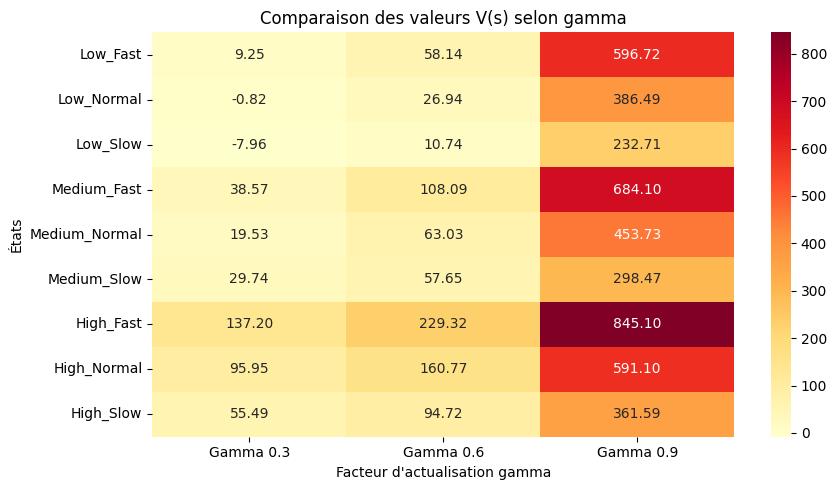

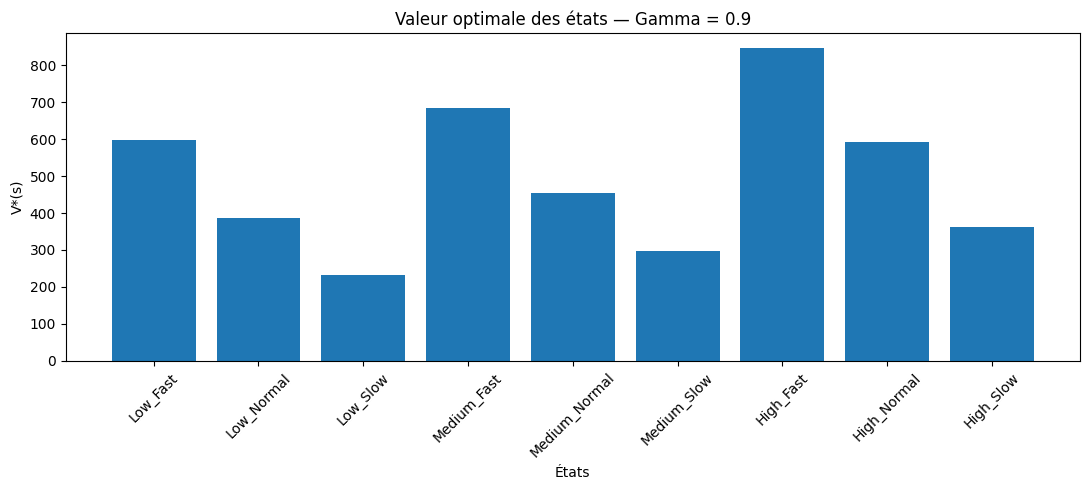

,Etat,Gamma 0.3,Gamma 0.6,Gamma 0.9
0,Low_Fast,nothing,pub,pub
1,Low_Normal,nothing,pub,pub
2,Low_Slow,pub,pub,pub
3,Medium_Fast,promo,promo,promo
4,Medium_Normal,nothing,promo,promo
5,Medium_Slow,promo,promo,promo
6,High_Fast,rec,rec,rec
7,High_Normal,rec,rec,rec
8,High_Slow,nothing,rec,rec


/tmp/ipykernel_59313/1128407378.py:78: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  policy_numeric = policy_compare.set_index("Etat").replace(action_map)


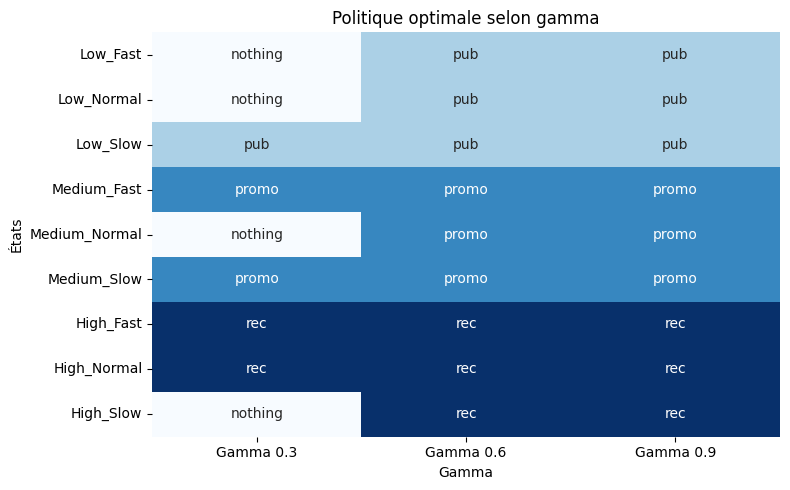

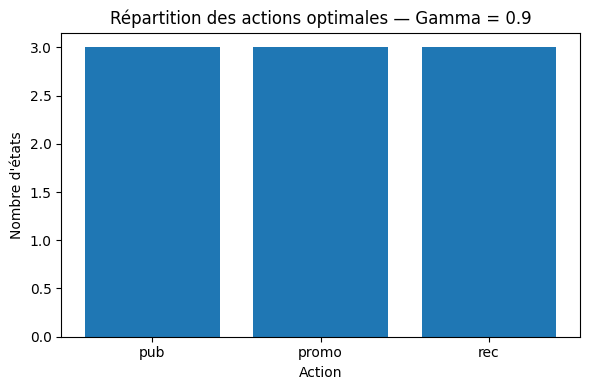

In [7]:
# =========================================
# VISUALISATION MDP — VALUE ITERATION
# =========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# =====================================================
# 1. Tableau des valeurs V(s) pour chaque gamma
# =====================================================

V_compare = pd.DataFrame({
    "Etat": states,
    "Gamma 0.3": all_results[0.3]["V(s)"].values,
    "Gamma 0.6": all_results[0.6]["V(s)"].values,
    "Gamma 0.9": all_results[0.9]["V(s)"].values
})

V_compare = V_compare.set_index("Etat")

display(V_compare)

# =====================================================
# 2. Heatmap des valeurs
# =====================================================

plt.figure(figsize=(9, 5))
sns.heatmap(
    V_compare,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd"
)
plt.title("Comparaison des valeurs V(s) selon gamma")
plt.xlabel("Facteur d'actualisation gamma")
plt.ylabel("États")
plt.tight_layout()
plt.show()

# =====================================================
# 3. Barplot V(s) pour gamma = 0.9
# =====================================================

plt.figure(figsize=(11, 5))
plt.bar(
    all_results[0.9]["Etat"],
    all_results[0.9]["V(s)"]
)
plt.title("Valeur optimale des états — Gamma = 0.9")
plt.xlabel("États")
plt.ylabel("V*(s)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# =====================================================
# 4. Politique optimale par gamma
# =====================================================

policy_compare = pd.DataFrame({
    "Etat": states,
    "Gamma 0.3": all_results[0.3]["Action optimale"].values,
    "Gamma 0.6": all_results[0.6]["Action optimale"].values,
    "Gamma 0.9": all_results[0.9]["Action optimale"].values
})

display(policy_compare)

# Transformer actions en nombres pour heatmap
action_map = {
    "nothing": 0,
    "pub": 1,
    "promo": 2,
    "rec": 3
}

policy_numeric = policy_compare.set_index("Etat").replace(action_map)

plt.figure(figsize=(8, 5))
sns.heatmap(
    policy_numeric,
    annot=policy_compare.set_index("Etat"),
    fmt="",
    cmap="Blues",
    cbar=False
)
plt.title("Politique optimale selon gamma")
plt.xlabel("Gamma")
plt.ylabel("États")
plt.tight_layout()
plt.show()

# =====================================================
# 5. Distribution des actions pour gamma = 0.9
# =====================================================

action_counts = all_results[0.9]["Action optimale"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(action_counts.index, action_counts.values)
plt.title("Répartition des actions optimales — Gamma = 0.9")
plt.xlabel("Action")
plt.ylabel("Nombre d'états")
plt.tight_layout()
plt.show()